<a href="https://colab.research.google.com/github/kelvincleophace0309/COU07506-labs/blob/main/COU07506_Week03_240141484517.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COU 07506 DSP, Week 03: Lab 1B (Convolution, Correlation and Difference Equations)
Name: Kelvin K Cleophace
Registration No.: 240141484517
Class: BENG24COE  Date: 25/11/2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
import time
plt.rcParams["figure.figsize"] = (9, 3.5)

In [3]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print(conv([1, 2, 3, 1], [1, 1, 1]))          # expect [1 3 6 6 4 1]
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]


In [4]:
print(conv([1, -1, 2], [2, 1, 0, 1]))
print(np.convolve([1, -1, 2], [2, 1, 0, 1]))

[ 2. -1.  3.  3. -1.  2.]
[ 2 -1  3  3 -1  2]


In [5]:
rng = np.random.default_rng(0)
x = rng.standard_normal(2000)
h = rng.standard_normal(2000)

t0 = time.perf_counter()
y1 = conv(x, h)
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
y2 = np.convolve(x, h)
t_np = time.perf_counter() - t0

print(f"my double loop : {t_loop:.4f} s")
print(f"np.convolve    : {t_np:.6f} s")
print(f"np.convolve is about {t_loop/t_np:.0f} times faster")
print("same result:", np.allclose(y1, y2))

my double loop : 5.3820 s
np.convolve    : 0.002740 s
np.convolve is about 1964 times faster
same result: True


M =  3 | error against clean sine = 0.302
M =  9 | error against clean sine = 0.182
M = 25 | error against clean sine = 0.274


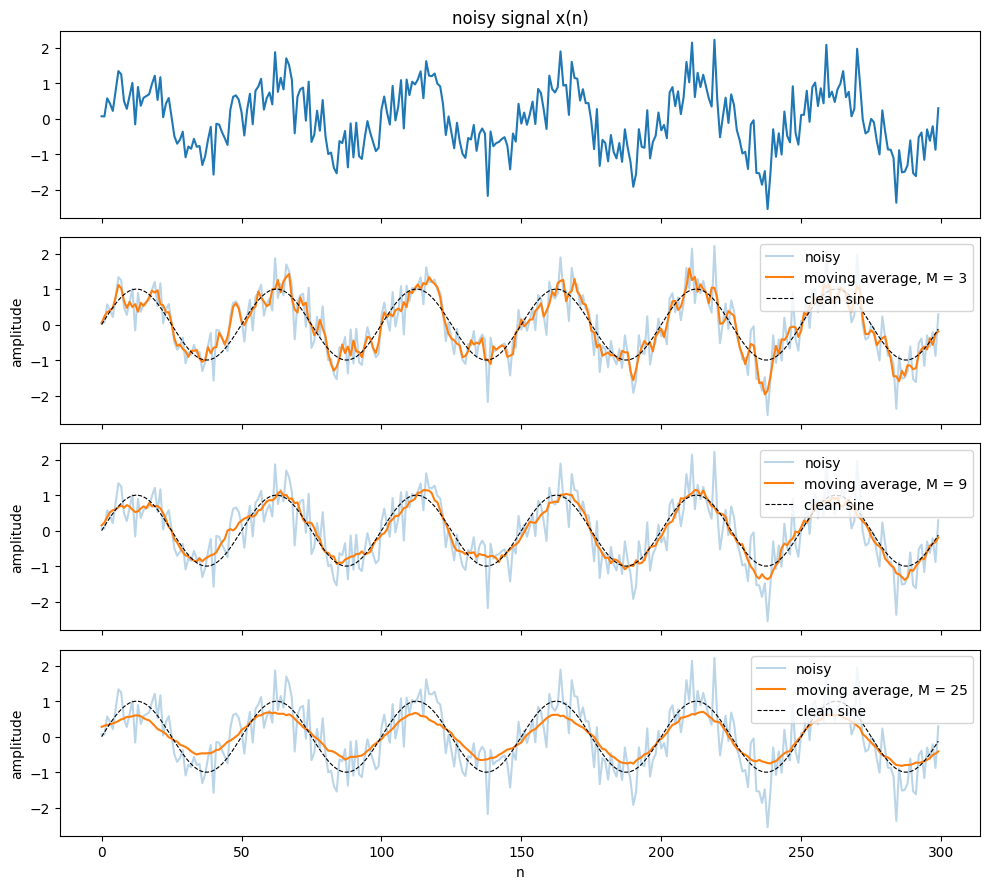

In [6]:
rng = np.random.default_rng(0)
n = np.arange(300)
clean = np.sin(2*np.pi*n/50)
x = clean + 0.5*rng.standard_normal(300)

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
axes[0].plot(n, x); axes[0].set_title("noisy signal x(n)")
for ax, M in zip(axes[1:], [3, 9, 25]):
    h = np.ones(M)/M
    y = np.convolve(x, h, mode="same")
    err = np.sqrt(np.mean((y[30:-30] - clean[30:-30])**2))
    ax.plot(n, x, alpha=0.3, label="noisy")
    ax.plot(n, y, label=f"moving average, M = {M}")
    ax.plot(n, clean, "k--", lw=0.8, label="clean sine")
    ax.legend(loc="upper right"); ax.set_ylabel("amplitude")
    print(f"M = {M:2d} | error against clean sine = {err:.3f}")
axes[-1].set_xlabel("n")
plt.tight_layout(); plt.show()

In [7]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}
for name, T in systems.items():
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


noise std = 0.5 -> estimated delay =   37 samples (OK)
noise std =   1 -> estimated delay =   37 samples (OK)
noise std =   2 -> estimated delay =   37 samples (OK)
noise std =   4 -> estimated delay =   37 samples (OK)


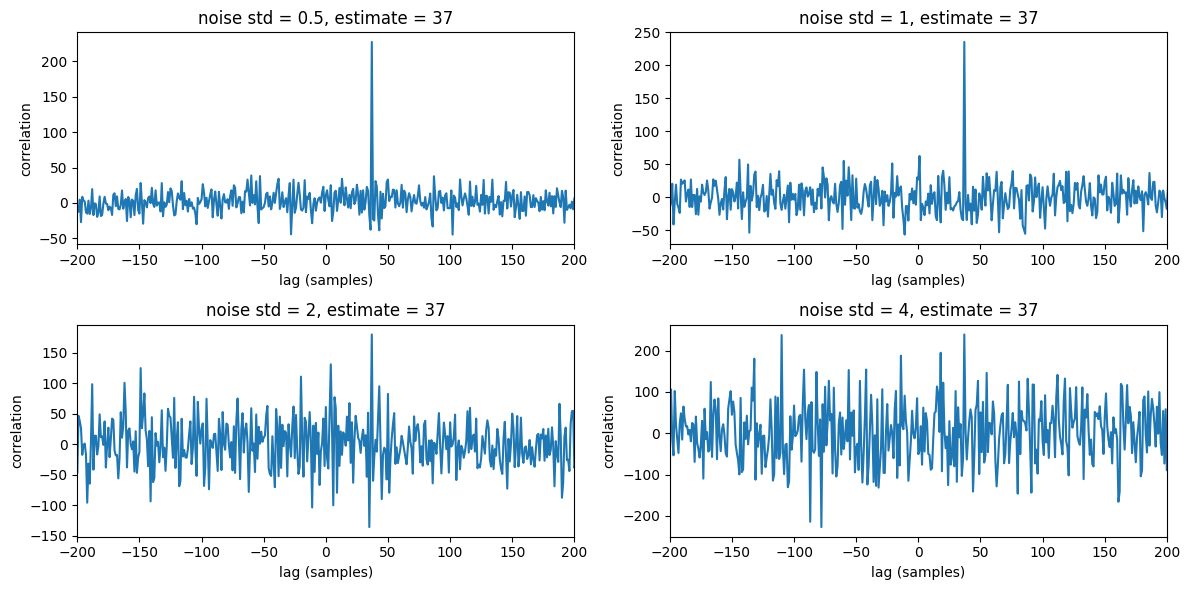

delay = 37 ms, distance = 343 x 0.037 = 12.69 m


In [8]:
fs = 1000
true_delay = 37
rng = np.random.default_rng(1)
x = rng.standard_normal(500)

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, sigma in zip(axes.flat, [0.5, 1, 2, 4]):
    y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + sigma*rng.standard_normal(500)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    est = lags[np.argmax(r)]
    status = "OK" if est == true_delay else "FAILED"
    print(f"noise std = {sigma:>3} -> estimated delay = {est:4d} samples ({status})")
    ax.plot(lags, r); ax.set_xlim(-200, 200)
    ax.set_title(f"noise std = {sigma}, estimate = {est}")
    ax.set_xlabel("lag (samples)"); ax.set_ylabel("correlation")
plt.tight_layout(); plt.show()

delay_s = true_delay / fs
print(f"delay = {delay_s*1000:.0f} ms, distance = 343 x {delay_s:.3f} = {343*delay_s:.2f} m")

recursion  : [1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
lfilter    : [1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
closed form: [1.     1.75   1.1875 0.6719 0.3555 0.1826 0.0925 0.0466 0.0234 0.0117]
all three match: True


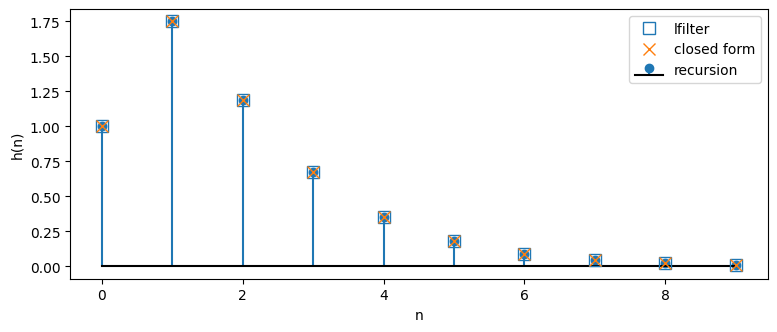

final value of step response: 5.3333
H(1) = sum(b)/sum(a)        : 5.3333


In [9]:
N = 10
impulse = np.zeros(N); impulse[0] = 1
n = np.arange(N)

# 1. direct recursion: h(n) = d(n) + d(n-1) + 0.75 h(n-1) - 0.125 h(n-2)
h_rec = np.zeros(N)
for k in range(N):
    xk  = impulse[k]
    xk1 = impulse[k-1] if k >= 1 else 0
    y1  = h_rec[k-1] if k >= 1 else 0
    y2  = h_rec[k-2] if k >= 2 else 0
    h_rec[k] = xk + xk1 + 0.75*y1 - 0.125*y2

# 2. lfilter
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)

# 3. closed form
h_cf = 6*0.5**n - 5*0.25**n

print("recursion  :", np.round(h_rec, 4))
print("lfilter    :", np.round(h_lf, 4))
print("closed form:", np.round(h_cf, 4))
print("all three match:", np.allclose(h_rec, h_lf) and np.allclose(h_lf, h_cf))

plt.stem(n, h_rec, linefmt="C0-", markerfmt="C0o", basefmt="k-", label="recursion")
plt.plot(n, h_lf, "s", ms=9, mfc="none", label="lfilter")
plt.plot(n, h_cf, "x", ms=8, label="closed form")
plt.xlabel("n"); plt.ylabel("h(n)"); plt.legend(); plt.show()

# 4. step response and final value
step_resp = signal.lfilter([1, 1], [1, -0.75, 0.125], np.ones(60))
print("final value of step response:", round(step_resp[-1], 4))
print("H(1) = sum(b)/sum(a)        :", round(2/(1 - 0.75 + 0.125), 4))

In [10]:
rng = np.random.default_rng(5)
x = rng.standard_normal(500)
print("noise std | correct estimates out of 20 trials")
for sigma in [4, 6, 8, 12, 16, 24]:
    ok = 0
    for trial in range(20):
        y = np.concatenate([np.zeros(37), 0.6*x])[:500] + sigma*rng.standard_normal(500)
        r = signal.correlate(y, x, mode="full")
        lags = signal.correlation_lags(len(y), len(x), mode="full")
        ok += (lags[np.argmax(r)] == 37)
    print(f"{sigma:9d} | {ok}/20")

noise std | correct estimates out of 20 trials
        4 | 12/20
        6 | 8/20
        8 | 3/20
       12 | 1/20
       16 | 1/20
       24 | 0/20


## Pre-lab
(a) x(n) = {1, -1, 2} convolved with h(n) = {2, 1, 0, 1} gives y(n) = {2, -1, 3, 3, -1, 2}. The length is 3 + 4 - 1 = 6. I checked it with np.convolve and it matched.
(b) y(n) = n x(n) is NOT time-invariant. If the input is delayed by n0, the new output is n x(n - n0). But delaying the original output gives (n - n0) x(n - n0). These are different, so the system is not time-invariant.

## Task 3.1: Timing
For two random sequences of length 2000, my double loop took 5.38 s and np.convolve took 0.00274 s. np.convolve was about 1964 times faster, and both gave the same result.

## Task 3.2: Smoothing observation
The error against the clean sine was 0.302 for M = 3, 0.182 for M = 9 and 0.274 for M = 25. M = 9 gave the best result. A bigger M removes more noise, but it also flattens the real signal: with M = 25 the peaks of the sine became lower, so the signal is distorted. There is a trade-off between noise reduction and distortion.

## Task 3.3: Linearity and time-invariance
x^2 is time-invariant but not linear. n x(n) is linear but not time-invariant. The moving average is both linear and time-invariant.

## Task 3.4: Cross-correlation
The estimated delay was 37 samples for noise std 0.5, 1, 2 and 4 in the first run, which equals the true delay. When I repeated the test 20 times for each noise level, the estimate was correct 12 out of 20 times at noise std 4, 8 out of 20 at std 6 and only 3 out of 20 at std 8. So the estimate starts to fail at about noise std 4 and is unreliable from std 6 upward. This happens because the noise peaks in the correlation become as large as the true peak at lag 37. The delay of 37 samples at fs = 1000 Hz is 37 ms, so the distance is 343 x 0.037 = 12.69 m.

## Task 3.5: Difference equation
The impulse responses from recursion, lfilter and the closed form h(n) = 6(0.5)^n - 5(0.25)^n all matched (1, 1.75, 1.1875, 0.6719, ...). The final value of the step response was 5.3333, which agrees with H(1) = sum(b)/sum(a) = 2/0.375 = 5.3333.

## Analysis Question 1
np.convolve is much faster because it is written in compiled, optimised C code, while my double loop runs in slow interpreted Python. For lengths L and M, direct convolution needs L x M multiplications (here 2000 x 2000 = 4,000,000).

## Analysis Question 2
Only the moving average is LTI. x^2 is time-invariant but not linear, because squaring does not satisfy superposition. n x(n) is linear but not time-invariant, because the multiplier n changes with time. The moving average is a weighted sum of delayed inputs with fixed weights, so it is both linear and time-invariant. I could have predicted this without code: a squared term makes a system nonlinear, and a coefficient that depends on n makes it time-varying.

## Analysis Question 3
(1) Locating leaks in water pipes: two sensors on the pipe record the leak noise, and the cross-correlation peak gives the time difference, which gives the distance to the leak. (2) GPS and radar: the received signal is correlated with a known transmitted code, and the peak gives the delay, which gives the distance.

## Analysis Question 4
The system is IIR. The feedback terms make the impulse response h(n) = 6(0.5)^n - 5(0.25)^n infinitely long. It is stable because the poles are at 0.5 and 0.25, both inside the unit circle, so h(n) decays to zero and its absolute sum is finite.

## AI-use statement
AI tools used: Claude
Used for: Guidance on running Tasks 3.1 to 3.5 in Colab
How I verified the output: compared my results with the expected values in the lab manual, checked np.convolve against my own conv function, and checked the impulse responses three different ways
I confirm that I understand and can explain all submitted code.